In [1]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.interpolate import PchipInterpolator

try:
    from IPython.display import display
except ImportError:
    display = print

MOLECULES = ("H2O2", "H2S2", "H2Se2")
LABELS = {
    "H2O2": r"H$_2$O$_2$",
    "H2S2": r"H$_2$S$_2$",
    "H2Se2": r"H$_2$Se$_2$",
}

# Set H2X2_PROJECT_ROOT before running, or edit the fallback below.
PROJECT_ROOT = Path(os.environ.get(
    "H2X2_PROJECT_ROOT", Path.cwd()/"H2X2_publication_project"
)).resolve()

DVR_PATHS = {
    molecule: PROJECT_ROOT/"data"/molecule/"processed"/"dvr_wavefunctions.npz"
    for molecule in MOLECULES
}
ALPHA_PATHS = {
    molecule: PROJECT_ROOT/"data"/molecule/"processed"/"polarizability_surface.npz"
    for molecule in MOLECULES
}

FIGURE_DIR = PROJECT_ROOT/"figures"
RESULTS_DIR = PROJECT_ROOT/"results"/"manuscript_assets"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

HARTREE_TO_CM = 219474.6313705
HARTREE_J = 4.3597447222060e-18
AMU_TO_ME = 1822.888486209
N_EIGENPAIRS_FOR_RECONSTRUCTION = 24

# Production splittings already established by the relaxed-path Fourier-DVR runs.
REPORTED_SPLIT_CM = {
    "H2O2": 10.984,
    "H2S2": 5.636e-6,
    "H2Se2": 1.743e-6,
}

# Values printed for the one-period ground-pair overlaps in the current draft.
# Remove or update them only if you also update the manuscript table.
TABLE_ABS_A01_AU = {"H2O2": 1.5652, "H2S2": 2.2715, "H2Se2": 2.4941}
TABLE_ABS_TOL_AU = 5e-4  # Figure values must agree at the reported precision.
TRANS_CUTOFF_DEG = 5.0  # Manuscript: omit points this close to trans.

# Colorblind-safe and print-friendly; one color is retained for each molecule.
COLORS = {
    "H2O2": "#0072B2",
    "H2S2": "#E69F00",
    "H2Se2": "#CC79A7",
}
DARK = "#1F2933"
GRAY = "#6B7280"
LIGHT_GRAY = "#D8DEE6"
POSITIVE_FILL_ALPHA = 0.28
NEGATIVE_COLOR = "#9CA3AF"

mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.facecolor": "white",
    "font.family": "serif",
    "font.serif": ["STIX Two Text", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8.5,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9.5,
    "xtick.labelsize": 7.6,
    "ytick.labelsize": 7.6,
    "axes.linewidth": 0.75,
    "lines.linewidth": 1.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def panel_label(ax, label):
    ax.text(-0.16, 1.06, label, transform=ax.transAxes, weight="bold",
            fontsize=9.5, va="top", ha="left")

def style_axis(ax):
    ax.grid(True, axis="y", color=LIGHT_GRAY, lw=0.45, alpha=0.60)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)

def save_figure(fig, stem):
    outputs = []
    for suffix, kwargs in (("pdf", {}), ("png", {"dpi": 600})):
        path = FIGURE_DIR/f"{stem}.{suffix}"
        fig.savefig(path, bbox_inches="tight", **kwargs)
        outputs.append(path)
        print("wrote", path)
    return outputs

required = [*DVR_PATHS.values(), *ALPHA_PATHS.values()]
missing = [str(path) for path in required if not path.exists()]
print("Project root:", PROJECT_ROOT)
if missing:
    raise FileNotFoundError(
        "Missing production inputs. Set H2X2_PROJECT_ROOT to the directory containing "
        "data/<molecule>/processed/:\n  " + "\n  ".join(missing)
    )


Project root: /home/smohtash/H2X2_final/H2X2_publication_project


In [2]:
def first_key(archive, names):
    for name in names:
        if name in archive.files:
            return name
    return None

def wrap_pi(values):
    return (np.asarray(values, float) + np.pi) % (2*np.pi) - np.pi

def orient_states(array, ngrid, name):
    array = np.asarray(array, complex)
    if array.ndim != 2:
        raise ValueError(f"{name} must be a matrix, got {array.shape}")
    if array.shape[0] == ngrid:
        return array
    if array.shape[1] == ngrid:
        return array.T
    raise ValueError(f"{name} shape {array.shape} is incompatible with {ngrid} grid points")

def normalize_columns(U):
    U = np.asarray(U, complex)
    norms = np.sqrt(np.sum(abs(U)**2, axis=0))
    if np.any(norms < 1e-14):
        raise ValueError("A DVR eigenvector has zero norm")
    return U/norms

def parity_aware_interp(x_source, y_source, x_target, antiperiodic=False):
    # Interpolate a 2pi-periodic or 2pi-antiperiodic body-fixed quantity.
    xs = wrap_pi(x_source)
    ys = np.asarray(y_source, float)
    order = np.argsort(xs)
    xs, ys = xs[order], ys[order]
    keep = np.r_[True, np.diff(xs) > 1e-10]
    xs, ys = xs[keep], ys[keep]
    boundary_sign = -1.0 if antiperiodic else 1.0
    xext = np.r_[xs[-1]-2*np.pi, xs, xs[0]+2*np.pi]
    yext = np.r_[boundary_sign*ys[-1], ys, boundary_sign*ys[0]]
    return np.interp(wrap_pi(x_target), xext, yext)

def retained_positive_alpha_samples(phi_source, ayz_source):
    """Positive-angle electronic points outside the excluded trans region."""
    phi_source = np.asarray(phi_source, float)
    ayz_source = np.asarray(ayz_source, float)
    limit = np.pi - np.radians(TRANS_CUTOFF_DEG)
    mask = (phi_source > 1e-12) & (phi_source < limit)
    xp = phi_source[mask]
    yp = ayz_source[mask]
    if len(xp) < 3:
        raise ValueError("Too few positive-angle alpha_yz samples after cutoff")
    order = np.argsort(xp)
    xp, yp = xp[order], yp[order]
    keep = np.r_[True, np.diff(xp) > 1e-10]
    xp, yp = xp[keep], yp[keep]
    return xp, yp


def odd_alpha_with_trans_cutoff(phi_source, ayz_source, phi_target):
    """Operator surface: reproduce the manuscript's zero-trans convention."""
    xp, yp = retained_positive_alpha_samples(phi_source, ayz_source)
    x = np.r_[0.0, xp, np.pi]
    y = np.r_[0.0, yp, 0.0]
    return np.sign(phi_target)*PchipInterpolator(x, y)(np.abs(phi_target))


def odd_alpha_for_display(phi_source, ayz_source, phi_target):
    """Display the data-supported surface without the artificial zero anchor."""
    xp, yp = retained_positive_alpha_samples(phi_source, ayz_source)
    target = np.asarray(phi_target, float)
    visible = np.abs(target) <= xp[-1] + 1e-12
    display = np.full(target.shape, np.nan)
    display[visible] = (
        np.sign(target[visible])
        *PchipInterpolator(np.r_[0.0, xp], np.r_[0.0, yp])(
            np.abs(target[visible])
        )
    )
    return display, float(np.degrees(xp[-1]))


def fourier_kinetic_unit(ngrid, twist):
    # Dimensionless -d^2/(2 dchi^2) matrix for periodic/twisted Fourier DVR.
    chi = -np.pi + 2*np.pi*np.arange(ngrid)/ngrid
    modes = np.fft.fftfreq(ngrid, d=1.0/ngrid) + float(twist)
    F = np.exp(1j*np.outer(chi, modes))/np.sqrt(ngrid)
    K = (F*(modes**2)) @ F.conj().T
    return 0.5*(K + K.conj().T)

def parity_matrix(ngrid, translation_sign):
    # Reflection operator in a sector with psi(chi+2pi)=s psi(chi).
    P = np.zeros((ngrid, ngrid), complex)
    for j in range(ngrid):
        P[j, 0 if j == 0 else ngrid-j] = translation_sign if j == 0 else 1.0
    if not np.allclose(P, P.conj().T) or not np.allclose(P@P, np.eye(ngrid)):
        raise RuntimeError("Parity operator construction failed")
    return P

def reconstruct_constant_mass_model(U, energies_ha):
    # Recover A and V in H=A K+V from saved periodic eigenpairs.
    U = normalize_columns(U)
    energies_ha = np.asarray(energies_ha, float)
    nuse = min(U.shape[1], len(energies_ha), N_EIGENPAIRS_FOR_RECONSTRUCTION)
    U = U[:, :nuse]
    energies_ha = energies_ha[:nuse]
    K0 = fourier_kinetic_unit(U.shape[0], 0.0)
    KU = K0@U
    Y = U*energies_ha[None, :]
    density = np.sum(abs(U)**2, axis=1)
    if np.min(density) < 1e-14:
        raise RuntimeError("Saved eigenpairs are insufficient to reconstruct V(chi)")
    v0 = np.real(np.sum(U.conj()*Y, axis=1))/density
    v1 = np.real(np.sum(U.conj()*KU, axis=1))/density
    R0 = Y-v0[:, None]*U
    R1 = KU-v1[:, None]*U
    A = float(np.vdot(R1, R0).real/np.vdot(R1, R1).real)
    V = np.real(v0-A*v1)
    Hfit = A*K0+np.diag(V)
    residuals_cm = np.array([
        np.linalg.norm(Hfit@U[:, k]-energies_ha[k]*U[:, k])*HARTREE_TO_CM
        for k in range(nuse)
    ])
    if A <= 0:
        raise RuntimeError(f"Recovered a nonphysical kinetic coefficient A={A}")
    return A, V, residuals_cm

def direct_or_reconstructed_model(dz, U, energies, sort_index):
    potential_key = first_key(dz, (
        "V_ha", "V_hartree", "V_grid_ha", "V_phi_ha",
        "potential_ha", "potential_hartree", "V_chi_ha",
    ))
    kinetic_key = first_key(dz, (
        "kinetic_prefactor_ha", "A_kin_ha", "B_kin_ha", "hbar2_over_2I_ha",
    ))
    inertia_amu_key = first_key(dz, ("I_const_amu_bohr2", "I_amu_bohr2"))
    inertia_au_key = first_key(dz, ("I_const_au", "I_chi_au"))
    if potential_key is not None and (kinetic_key or inertia_amu_key or inertia_au_key):
        V = np.asarray(dz[potential_key], float)[sort_index]
        if kinetic_key:
            A = float(np.asarray(dz[kinetic_key]).reshape(-1)[0])
        elif inertia_amu_key:
            inertia = float(np.asarray(dz[inertia_amu_key]).reshape(-1)[0])*AMU_TO_ME
            A = 1/(2*inertia)
        else:
            inertia = float(np.asarray(dz[inertia_au_key]).reshape(-1)[0])
            A = 1/(2*inertia)
        H = A*fourier_kinetic_unit(len(V), 0.0)+np.diag(V)
        residuals = np.array([
            np.linalg.norm(H@U[:, k]-energies[k]*U[:, k])*HARTREE_TO_CM
            for k in range(min(U.shape[1], len(energies)))
        ])
        source = f"direct: {potential_key}"
    else:
        A, V, residuals = reconstruct_constant_mass_model(U, energies)
        source = "reconstructed from saved periodic eigenpairs"
    return A, V, residuals, source

def corrected_even_c2_dipole(molecule, phi_raw, sort_index):
    path = PROJECT_ROOT / "data" / molecule / "raw" / "torsion_scan.csv"
    scan = pd.read_csv(path).sort_values("phi_deg")

    phi_scan = np.radians(scan["phi_deg"].to_numpy(dtype=float))
    mu_y = scan["mu_y_D"].to_numpy(dtype=float)
    mu_z = scan["mu_z_D"].to_numpy(dtype=float)

    if not np.all(np.diff(phi_scan) > 0):
        raise ValueError(f"{molecule}: scan angles must be unique and increasing")
    if not (np.isclose(phi_scan[0], 0) and np.isclose(phi_scan[-1], np.pi)):
        raise ValueError(f"{molecule}: scan must include cis and trans")
    if not np.all(np.isfinite(mu_y)) or not np.all(np.isfinite(mu_z)):
        raise ValueError(f"{molecule}: missing Cartesian PBE0 dipoles")

    # C2 direction for the positive-angle production geometries.
    mu_c2_scan = np.cos(phi_scan / 2) * mu_y + np.sin(phi_scan / 2) * mu_z

    phi = wrap_pi(phi_raw)[sort_index]
    mu_c2_grid = PchipInterpolator(phi_scan, mu_c2_scan)(np.abs(phi))

    print(f"{molecule}: C2 dipole at cis = {mu_c2_scan[0]:.4f} D; "
          f"at trans = {mu_c2_scan[-1]:.4f} D")
    return mu_c2_grid, f"C2 projection of Cartesian PBE0 dipole in {path}"

def load_model(molecule):
    with np.load(DVR_PATHS[molecule], allow_pickle=False) as dz:
        angle_key = first_key(dz, (
            "phi_rad", "phi_grid_rad", "phi_of_chi_rad", "phi_chi_rad",
            "physical_phi_rad", "phi_dvr_rad",
        ))
        if angle_key is None:
            degree_key = first_key(dz, ("phi_deg", "phi_grid_deg", "physical_phi_deg"))
            if degree_key is None:
                raise KeyError(f"{molecule}: physical dihedral grid not found")
            phi_raw = np.radians(np.asarray(dz[degree_key], float))
        else:
            phi_raw = np.asarray(dz[angle_key], float)

        Ee = np.asarray(dz["Ee_ha"], float)
        Eo = np.asarray(dz["Eo_ha"], float)
        Pe = orient_states(dz["Pe"], len(phi_raw), "Pe")
        Po = orient_states(dz["Po"], len(phi_raw), "Po")
        sort_index = np.argsort(wrap_pi(phi_raw))
        phi = wrap_pi(phi_raw)[sort_index]
        Pe, Po = Pe[sort_index], Po[sort_index]
        Ulegacy = normalize_columns(np.column_stack([Pe, Po]))
        Elegacy = np.r_[Ee, Eo]
        order = np.argsort(Elegacy)
        Elegacy, Ulegacy = Elegacy[order], Ulegacy[:, order]
        A, Vraw, residuals, source = direct_or_reconstructed_model(
            dz, Ulegacy, Elegacy, sort_index
        )
        mu_c2_D, dipole_source = corrected_even_c2_dipole(
    molecule, phi_raw, sort_index
)

    ngrid = len(phi)
    chi = -np.pi+2*np.pi*np.arange(ngrid)/ngrid
    Pplus = parity_matrix(ngrid, +1)
    V = np.real(0.5*(Vraw+Pplus@Vraw))

    with np.load(ALPHA_PATHS[molecule], allow_pickle=False) as az:
        phi_a = np.asarray(az["phi_rad"], float)
        alpha_path = np.asarray(az["alpha_bf_au"], float)
    if alpha_path.shape != (len(phi_a), 3, 3):
        raise ValueError(f"{molecule}: unexpected polarizability shape {alpha_path.shape}")

    alpha = np.empty((ngrid, 3, 3), float)
    for i in range(3):
        for j in range(3):
            # The old interpolation is overwritten for yz below; diagonal data remain available.
            odd = ((i == 1) != (j == 1))
            alpha[:, i, j] = parity_aware_interp(
                phi_a, alpha_path[:, i, j], phi, antiperiodic=odd
            )
    alpha = 0.5*(alpha+np.swapaxes(alpha, 1, 2))
    # Replace the previous cross-sector interpolation by the one-period
    # trans-cutoff surface specified in the draft. The table comparison below
    # prevents plotting if this does not reproduce the published values.
    ayz = odd_alpha_with_trans_cutoff(phi_a, alpha_path[:, 1, 2], phi)
    ayz_display, display_edge_deg = odd_alpha_for_display(
        phi_a, alpha_path[:, 1, 2], phi
    )
    alpha[:, 1, 2] = ayz
    alpha[:, 2, 1] = ayz

    return {
        "molecule": molecule,
        "phi": phi,
        "chi": chi,
        "A_ha": A,
        "V_ha": V,
        "alpha": alpha,
        "alpha_yz_display": ayz_display,
        "alpha_display_edge_deg": display_edge_deg,
        "Pe0": normalize_columns(Pe)[:, 0],
        "Po0": normalize_columns(Po)[:, 0],
        "mu_c2_D": mu_c2_D,
        "dipole_source": dipole_source,
        "saved_split_cm": abs(Ee[0]-Eo[0])*HARTREE_TO_CM,
        "max_residual_cm": float(np.max(residuals)),
        "model_source": source,
    }

models = {molecule: load_model(molecule) for molecule in MOLECULES}


H2O2: C2 dipole at cis = 3.0755 D; at trans = -0.0000 D
H2S2: C2 dipole at cis = 1.6101 D; at trans = -0.0000 D
H2Se2: C2 dipole at cis = 0.9877 D; at trans = -0.0000 D


In [4]:
def odd_parity_error(phi, values):
    # The DVR interval is [-pi, pi): include its missing endpoint explicitly.
    reflected = np.interp(-phi, np.r_[phi, np.pi], np.r_[values, -values[0]])
    return float(np.max(np.abs(values+reflected)))


def even_parity_error(phi, values):
    reflected = np.interp(-phi, np.r_[phi, np.pi], np.r_[values, values[0]])
    return float(np.max(np.abs(values-reflected)))


input_audit = pd.DataFrame.from_records([
    {
        "molecule": molecule,
        "saved_ground_split_cm-1": model["saved_split_cm"],
        "alpha_yz_odd_abs_error_au": odd_parity_error(
            model["phi"], model["alpha"][:, 1, 2]),
        "mu_C2_even_abs_error_D": even_parity_error(
            model["phi"], model["mu_c2_D"]),
        "dipole_source": model["dipole_source"],
        "model_source": model["model_source"],
    }
    for molecule, model in models.items()
]).set_index("molecule")
display(input_audit)
input_audit.to_csv(RESULTS_DIR/"Fig03_input_audit.csv")


,saved_ground_split_cm-1,alpha_yz_odd_abs_error_au,mu_C2_even_abs_error_D,dipole_source,model_source
molecule,,,,,
H2O2,10.984173,1.998401e-15,4.440892e-16,C2 projection of Cartesian PBE0 dipole in /hom...,reconstructed from saved periodic eigenpairs
H2S2,0.000006,2.220446e-15,2.220446e-16,C2 projection of Cartesian PBE0 dipole in /hom...,reconstructed from saved periodic eigenpairs
H2Se2,0.000002,2.220446e-15,2.220446e-16,C2 projection of Cartesian PBE0 dipole in /hom...,reconstructed from saved periodic eigenpairs


In [5]:
selected = {}
for molecule, model in models.items():
    even = model["Pe0"]
    odd = model["Po0"]
    ayz = model["alpha"][:, 1, 2]
    raw = np.vdot(even, ayz*odd)
    if abs(raw) < 1e-10:
        raise RuntimeError(f"{molecule}: A_01 is unexpectedly zero")
    odd = odd*np.exp(-1j*np.angle(raw))
    selected[molecule] = {"even": even, "odd": odd,
                          "abs_A01": float(abs(np.vdot(even, ayz*odd))),
                          "split_cm": model["saved_split_cm"]}


In [6]:
def trapezoid_weights(x):
    """Periodic physical-angle quadrature weights, with x in radians."""
    x = np.asarray(x, float)
    if np.any(np.diff(x) <= 0):
        raise ValueError("The physical-angle grid must be strictly increasing")
    weights = np.empty_like(x)
    seam = x[0]+2*np.pi-x[-1]
    if seam <= 0:
        raise ValueError("Expected a one-period grid without the duplicated +pi point")
    weights[0] = 0.5*(x[1]-x[0]+seam)
    weights[-1] = 0.5*(x[-1]-x[-2]+seam)
    weights[1:-1] = 0.5*(x[2:]-x[:-2])
    return weights


def operator_contribution(model, pair, property_values):
    """Signed density per degree using DVR quadrature on one period."""
    even, odd = pair["even"], pair["odd"]
    discrete = np.real(np.conj(even)*property_values*odd)
    weights = trapezoid_weights(model["phi"])
    density = (np.pi/180.0)*discrete/weights
    weights_deg = np.degrees(weights)
    matrix_element = np.vdot(even, property_values*odd)
    return {"phi": model["phi"], "density": density,
            "integrated": float(np.sum(weights_deg*density)),
            "matrix_element": matrix_element,
            "left": float(np.sum(discrete[model["phi"] < 0])),
            "right": float(np.sum(discrete[model["phi"] > 0]))}


contributions = {
    molecule: operator_contribution(model, selected[molecule], model["alpha"][:, 1, 2])
    for molecule, model in models.items()
}
dipole_contributions = {
    molecule: operator_contribution(model, selected[molecule], model["mu_c2_D"])
    for molecule, model in models.items()
}

overlap_rows = []
for molecule in MOLECULES:
    pair = selected[molecule]
    part = contributions[molecule]
    dip = dipole_contributions[molecule]
    mismatch = abs(pair["abs_A01"] - TABLE_ABS_A01_AU[molecule])
    overlap_rows.append({
        "molecule": molecule,
        "same_states_for_dipole_and_alpha": True,
        "split_01_cm-1": pair["split_cm"],
        "abs_A01_yz_au": pair["abs_A01"],
        "table_abs_A01_yz_au": TABLE_ABS_A01_AU[molecule],
        "abs_table_discrepancy_au": mismatch,
        "density_integral_au": part["integrated"],
        "mu01_D": float(np.real(dip["matrix_element"])),
        "density_matrix_error_au": abs(part["integrated"] - np.real(part["matrix_element"])),
    })
overlap_summary = pd.DataFrame(overlap_rows).set_index("molecule")
display(overlap_summary)
overlap_summary.to_csv(RESULTS_DIR/"Fig03_oneperiod_overlap_audit.csv")

if (overlap_summary["abs_table_discrepancy_au"] > TABLE_ABS_TOL_AU).any():
    raise RuntimeError(
        "Same states are now used, but the alpha interpolation or input surface "
        "does not reproduce Table A_01 to its reported precision. Check the "
        "production table's interpolation, trans cutoff, and DVR data before "
        "placing these plots in the manuscript. Do not rescale the density."
    )


,same_states_for_dipole_and_alpha,split_01_cm-1,abs_A01_yz_au,table_abs_A01_yz_au,abs_table_discrepancy_au,density_integral_au,mu01_D,density_matrix_error_au
molecule,,,,,,,,
H2O2,True,10.984173,1.565223,1.5652,0.000023,1.565223,2.103441e-16,4.440892e-16
H2S2,True,0.000006,2.271509,2.2715,0.000009,2.271509,-1.019799e-16,0.000000e+00
H2Se2,True,0.000002,2.494079,2.4941,0.000021,2.494079,4.845194e-18,8.881784e-16


wrote /home/smohtash/H2X2_final/H2X2_publication_project/figures/Fig02_oneperiod_same_01_pair.pdf
wrote /home/smohtash/H2X2_final/H2X2_publication_project/figures/Fig02_oneperiod_same_01_pair.png


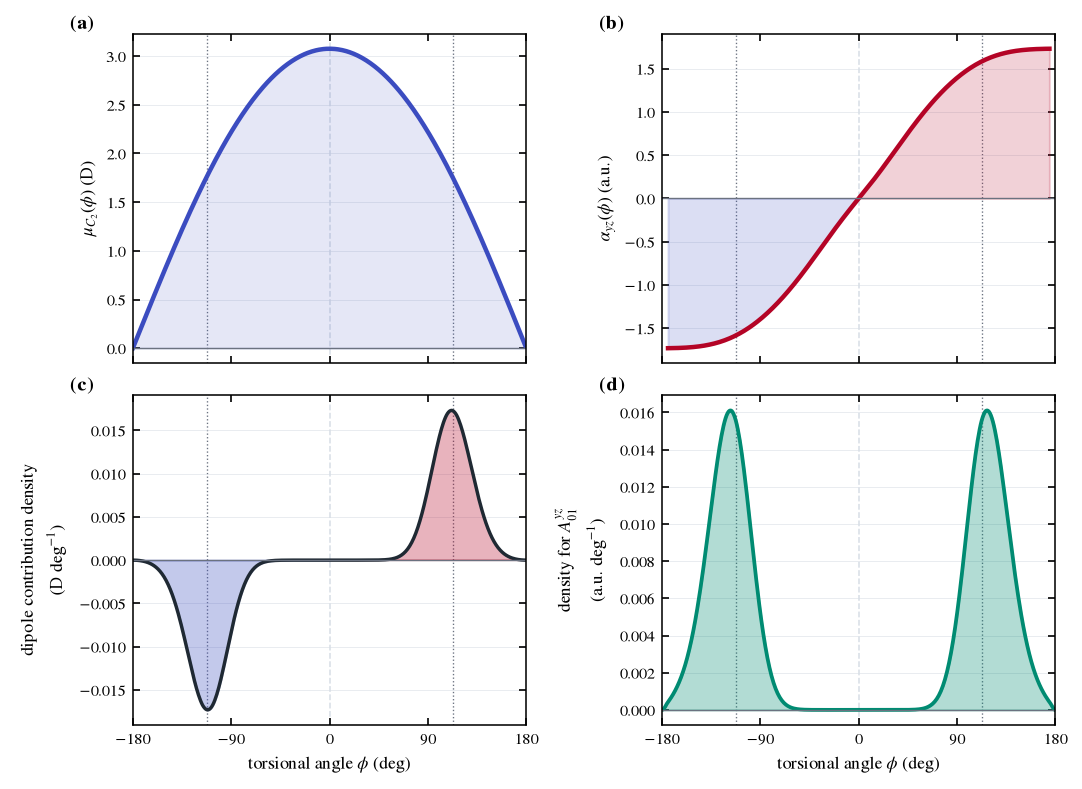

dipole_source                   C2 projection of Cartesian PBE0 dipole in /hom...
mu_C2_even_abs_error_D                                                        0.0
alpha_yz_odd_abs_error_au                                                     0.0
dipole_left_contribution_D                                              -0.791277
dipole_right_contribution_D                                              0.791277
dipole_total_D                                                                0.0
dipole_cancellation_residual                                                  0.0
oneperiod_A01_yz_au                                                      1.565223
Name: Figure 2 audit, dtype: object

In [7]:
def local_well_centres(model):
    phi = model["phi"]
    V = model["V_ha"]
    negative = np.where(phi < -np.radians(5))[0]
    positive = np.where(phi > np.radians(5))[0]
    if len(negative) == 0 or len(positive) == 0:
        return ()
    return (phi[negative[np.argmin(V[negative])]],
            phi[positive[np.argmin(V[positive])]])

reference_molecule = "H2O2"
reference = models[reference_molecule]
phi_deg = np.degrees(reference["phi"])
mu = reference["mu_c2_D"]
ayz = reference["alpha_yz_display"]
dipole_part = dipole_contributions[reference_molecule]
polarizability_part = contributions[reference_molecule]
wells = local_well_centres(reference)

fig2, axes2 = plt.subplots(
    2, 2, figsize=(7.10, 5.15), sharex=True, constrained_layout=True
)

# (a) Even permanent dipole.
ax = axes2[0, 0]
ax.plot(phi_deg, mu, color="#3B4CC0", lw=2.15)
ax.fill_between(phi_deg, 0, mu, color="#3B4CC0", alpha=0.13)
ax.axhline(0, color=GRAY, lw=0.65)
ax.set_ylabel(r"$\mu_{C_2}(\phi)$ (D)")
style_axis(ax)
panel_label(ax, "(a)")

# (b) Odd polarizability.
ax = axes2[0, 1]
surface_visible = np.isfinite(ayz)
ax.plot(phi_deg[surface_visible], ayz[surface_visible], color="#B40426", lw=2.15)
ax.fill_between(phi_deg[surface_visible], 0, ayz[surface_visible],
                where=ayz[surface_visible] >= 0,
                color="#B40426", alpha=0.18, interpolate=True)
ax.fill_between(phi_deg[surface_visible], 0, ayz[surface_visible],
                where=ayz[surface_visible] < 0,
                color="#3B4CC0", alpha=0.18, interpolate=True)
ax.axhline(0, color=GRAY, lw=0.65)
ax.set_ylabel(r"$\alpha_{yz}(\phi)$ (a.u.)")
style_axis(ax)
panel_label(ax, "(b)")

# (c) Dipole contributions: opposite signs in the two wells.
ax = axes2[1, 0]
density = dipole_part["density"]
ax.plot(phi_deg, density, color=DARK, lw=1.65)
ax.fill_between(phi_deg, 0, density, where=density >= 0,
                color="#B40426", alpha=0.30, interpolate=True)
ax.fill_between(phi_deg, 0, density, where=density < 0,
                color="#3B4CC0", alpha=0.30, interpolate=True)
ax.axhline(0, color=GRAY, lw=0.65)
ax.set_xlabel(r"torsional angle $\phi$ (deg)")
ax.set_ylabel("dipole contribution density\n" + r"(D deg$^{-1}$)")
style_axis(ax)
panel_label(ax, "(c)")

# (d) Same-pair one-period polarizability contributions.
ax = axes2[1, 1]
density = polarizability_part["density"]
ax.plot(phi_deg, density, color="#008B72", lw=1.80)
ax.fill_between(phi_deg, 0, density, where=density >= 0,
                color="#008B72", alpha=0.30, interpolate=True)
ax.fill_between(phi_deg, 0, density, where=density < 0,
                color=NEGATIVE_COLOR, alpha=0.30, interpolate=True)
ax.axhline(0, color=GRAY, lw=0.65)
ax.set_xlabel(r"torsional angle $\phi$ (deg)")
ax.set_ylabel(r"density for $A_{01}^{yz}$" + "\n" + r"(a.u. deg$^{-1}$)")
style_axis(ax)
panel_label(ax, "(d)")

for ax in axes2.flat:
    ax.axvline(0, color=LIGHT_GRAY, lw=0.75, ls="--", zorder=0)
    for centre in wells:
        ax.axvline(np.degrees(centre), color=GRAY, lw=0.65, ls=":", zorder=0)
    ax.set_xlim(-180, 180)
    ax.set_xticks((-180, -90, 0, 90, 180))

figure2_outputs = save_figure(fig2, "Fig02_oneperiod_same_01_pair")
plt.show()

figure2_audit = pd.Series({
    "dipole_source": reference["dipole_source"],
    "mu_C2_even_abs_error_D": even_parity_error(reference["phi"], mu),
    "alpha_yz_odd_abs_error_au": odd_parity_error(reference["phi"], reference["alpha"][:, 1, 2]),
    "dipole_left_contribution_D": dipole_part["left"],
    "dipole_right_contribution_D": dipole_part["right"],
    "dipole_total_D": float(np.real(dipole_part["matrix_element"])),
    "dipole_cancellation_residual": abs(dipole_part["integrated"])/max(abs(dipole_part["left"])+abs(dipole_part["right"]), 1e-30),
    "oneperiod_A01_yz_au": selected[reference_molecule]["abs_A01"],
}, name="Figure 2 audit")
display(figure2_audit)
figure2_audit.to_csv(RESULTS_DIR/"Fig02_operator_audit.csv")


wrote /home/smohtash/H2X2_final/H2X2_publication_project/figures/Fig03_oneperiod_same_01_pair.pdf
wrote /home/smohtash/H2X2_final/H2X2_publication_project/figures/Fig03_oneperiod_same_01_pair.png


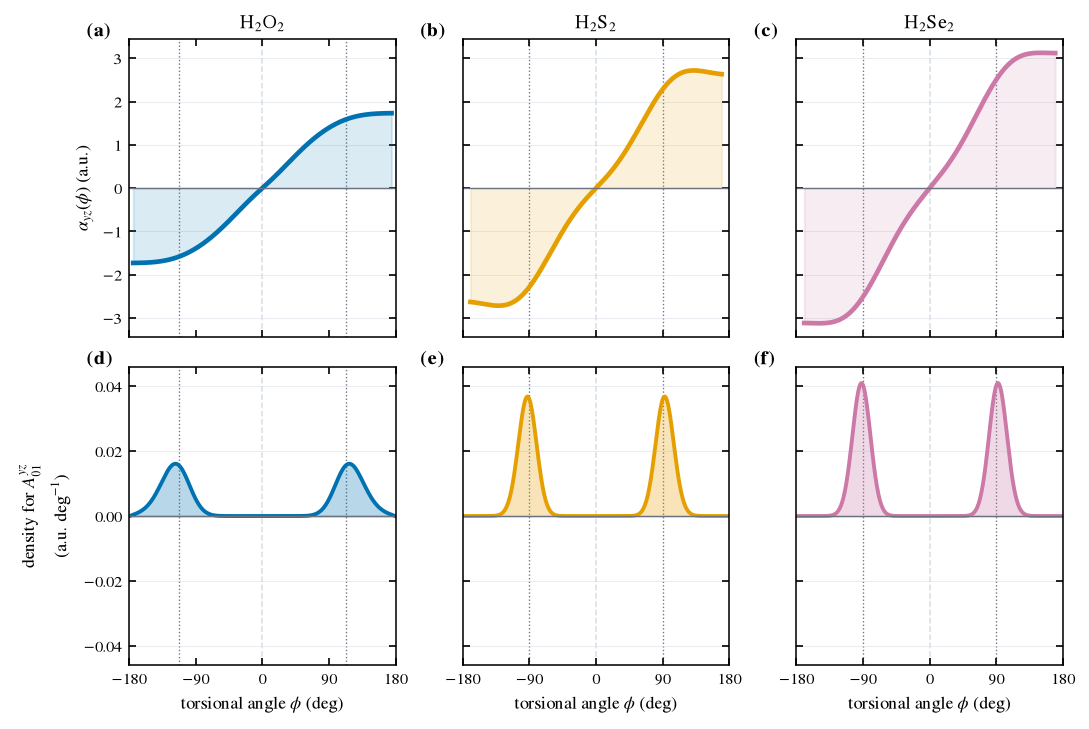

In [8]:
def well_centres(model):
    phi = model["phi"]
    V = model["V_ha"]
    negative = np.where(phi < -np.radians(5))[0]
    positive = np.where(phi > np.radians(5))[0]
    if len(negative) == 0 or len(positive) == 0:
        return ()
    return (phi[negative[np.argmin(V[negative])]],
            phi[positive[np.argmin(V[positive])]])

alpha_limit = 1.10*max(
    np.nanmax(np.abs(models[molecule]["alpha_yz_display"]))
    for molecule in MOLECULES
)
contribution_limit = 1.12*max(
    np.max(np.abs(contributions[molecule]["density"]))
    for molecule in MOLECULES
)

fig, axes = plt.subplots(
    2, 3, figsize=(7.15, 4.75), sharex=True, sharey="row",
    constrained_layout=True,
)
top_letters = ("a", "b", "c")
bottom_letters = ("d", "e", "f")

for column, molecule in enumerate(MOLECULES):
    model = models[molecule]
    color = COLORS[molecule]
    phi_deg = np.degrees(model["phi"])
    ayz = model["alpha_yz_display"]
    contribution = contributions[molecule]
    wells = well_centres(model)

    # Upper row: computed odd polarizability surface.
    ax = axes[0, column]
    surface_visible = np.isfinite(ayz)
    ax.plot(phi_deg[surface_visible], ayz[surface_visible], color=color, lw=2.25)
    ax.fill_between(phi_deg[surface_visible], 0, ayz[surface_visible],
                    where=ayz[surface_visible] >= 0,
                    color=color, alpha=0.14, interpolate=True)
    ax.fill_between(phi_deg[surface_visible], 0, ayz[surface_visible],
                    where=ayz[surface_visible] < 0,
                    color=color, alpha=0.14, interpolate=True)
    ax.axhline(0, color=GRAY, lw=0.65)
    ax.axvline(0, color=LIGHT_GRAY, lw=0.75, ls="--", zorder=0)
    for centre in wells:
        ax.axvline(np.degrees(centre), color=GRAY, lw=0.65, ls=":", zorder=0)
    ax.set_ylim(-alpha_limit, alpha_limit)
    ax.set_title(LABELS[molecule], pad=5)
    style_axis(ax)
    panel_label(ax, f"({top_letters[column]})")

    # Lower row: signed density of the same one-period 0/1 overlap.
    ax = axes[1, column]
    density = contribution["density"]
    ax.plot(phi_deg, density, color=color, lw=1.85)
    ax.fill_between(phi_deg, 0, density, where=density >= 0,
                    color=color, alpha=POSITIVE_FILL_ALPHA, interpolate=True,
                    label="reinforcing contribution")
    ax.fill_between(phi_deg, 0, density, where=density < 0,
                    color=NEGATIVE_COLOR, alpha=0.32, interpolate=True,
                    label="opposing contribution")
    ax.axhline(0, color=GRAY, lw=0.65)
    ax.axvline(0, color=LIGHT_GRAY, lw=0.75, ls="--", zorder=0)
    for centre in wells:
        ax.axvline(np.degrees(centre), color=GRAY, lw=0.65, ls=":", zorder=0)
    ax.set_ylim(-contribution_limit, contribution_limit)
    ax.set_xlim(-180, 180)
    ax.set_xticks((-180, -90, 0, 90, 180))
    ax.set_xlabel(r"torsional angle $\phi$ (deg)")

    style_axis(ax)
    panel_label(ax, f"({bottom_letters[column]})")

axes[0, 0].set_ylabel(r"$\alpha_{yz}(\phi)$ (a.u.)")
axes[1, 0].set_ylabel(
    r"density for $A_{01}^{yz}$" "\n" r"(a.u. deg$^{-1}$)"
)

outputs = save_figure(fig, "Fig03_oneperiod_same_01_pair")
plt.show()


In [9]:
alpha_maxima = [
    float(np.max(abs(models[molecule]["alpha"][:, 1, 2])))
    for molecule in MOLECULES
]
ref_phi = reference["phi"]
mu_density = dipole_part["density"]
alpha_density = polarizability_part["density"]

final_audit = pd.Series({
    "same_saved_even_odd_states_for_both_operators": True,
    "max_abs_table_A01_error_au": float(overlap_summary["abs_table_discrepancy_au"].max()),
    "dipole_cancellation_residual": float(figure2_audit["dipole_cancellation_residual"]),
    "dipole_density_odd_error": odd_parity_error(ref_phi, mu_density),
    "polarizability_density_even_error": even_parity_error(ref_phi, alpha_density),
    "max_density_quadrature_error": float(overlap_summary["density_matrix_error_au"].max()),
    "alpha_yz_magnitude_increases_O_to_Se": bool(alpha_maxima[0] < alpha_maxima[1] < alpha_maxima[2]),
    "figure2_pdf_written": figure2_outputs[0].exists() and figure2_outputs[0].stat().st_size > 0,
    "figure2_png_written": figure2_outputs[1].exists() and figure2_outputs[1].stat().st_size > 0,
    "figure3_pdf_written": outputs[0].exists() and outputs[0].stat().st_size > 0,
    "figure3_png_written": outputs[1].exists() and outputs[1].stat().st_size > 0,
}, name="Same-ground-pair figure audit")
display(final_audit)

if not (
    final_audit["dipole_cancellation_residual"] < 1e-6
    and final_audit["max_abs_table_A01_error_au"] <= TABLE_ABS_TOL_AU
    and final_audit["max_density_quadrature_error"] < 1e-10
    and final_audit["figure2_pdf_written"]
    and final_audit["figure2_png_written"]
    and final_audit["figure3_pdf_written"]
    and final_audit["figure3_png_written"]
):
    raise RuntimeError("Figures 2 or 3 failed an essential same-pair audit")

print("PASS: both density figures use the same saved 0/1 pair")
print("Figure 2:", *figure2_outputs)
print("Figure 3:", *outputs)
print("Table audit:", RESULTS_DIR/"Fig03_oneperiod_overlap_audit.csv")


same_saved_even_odd_states_for_both_operators        True
max_abs_table_A01_error_au                       0.000023
dipole_cancellation_residual                          0.0
dipole_density_odd_error                              0.0
polarizability_density_even_error                     0.0
max_density_quadrature_error                          0.0
alpha_yz_magnitude_increases_O_to_Se                 True
figure2_pdf_written                                  True
figure2_png_written                                  True
figure3_pdf_written                                  True
figure3_png_written                                  True
Name: Same-ground-pair figure audit, dtype: object

PASS: both density figures use the same saved 0/1 pair
Figure 2: /home/smohtash/H2X2_final/H2X2_publication_project/figures/Fig02_oneperiod_same_01_pair.pdf /home/smohtash/H2X2_final/H2X2_publication_project/figures/Fig02_oneperiod_same_01_pair.png
Figure 3: /home/smohtash/H2X2_final/H2X2_publication_project/figures/Fig03_oneperiod_same_01_pair.pdf /home/smohtash/H2X2_final/H2X2_publication_project/figures/Fig03_oneperiod_same_01_pair.png
Table audit: /home/smohtash/H2X2_final/H2X2_publication_project/results/manuscript_assets/Fig03_oneperiod_overlap_audit.csv
